# [실습] 토픽 검증표 — 테마로 쓸 토픽 고르기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 질문과 데이터

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">비정형 데이터(자연어) · 토픽 검증과 코드북</div>
<h1 style="color:#000000;margin:10px 0">토픽 검증표 — 테마로 쓸 토픽 고르기</h1>
<div style="font-size:1.05em;color:#656565">민원 2만 건의 토픽을 원문 읽기 · 시드 안정성 · 이름 확인으로 검증하고, 토픽 3 의 코드북 항목을 직접 씁니다</div>
</div>

**핵심 질문** 민원 토픽 가운데 어느 것을 테마로 쓰고, 테마의 코드북 항목을 어떻게 쓸까요?

이론에서 본 3가지 확인과 코드북 쓰기를 민원 2만 건에 직접 해 봅니다. 계산하는 코드는 모두 준비되어 있습니다. 출력을 읽고 판단을 적습니다.

1. **원문 읽기**: 토픽의 원문 5건을 읽고, 사건이 하나인지 여럿인지 정합니다.
2. **시드 안정성**: 시드를 바꾼 두 적합에서 토픽마다 대응 토픽이 있는지 봅니다.
3. **이름 확인**: 토픽 3 의 이름이 무작위 10건에 맞는지 한 건씩 확인하고 맞음 · 아님을 적습니다.
4. **코드북 항목 쓰기**: 1～3 단계에서 읽은 원문을 근거로 토픽 3 의 항목을 씁니다.

단계마다 설명을 읽고, 코드를 실행해 출력을 읽은 뒤, 직접 해 보기를 채웁니다. 직접 해 보기에서는 `MY_` 로 시작하는 변수를 채웁니다. 바로 아래 확인 셀을 실행하면 결과가 나옵니다.

**실행 안내**

- LMS 에서는 셀을 위에서부터 차례로 실행합니다. GPU 는 필요 없습니다.
- Colab 이나 내 컴퓨터에서 열었다면 맨 위 설치 셀부터 실행합니다. 처음 한 번은 원자료를 받느라 30초 안팎 걸립니다.
- 확인 셀은 변수를 아직 채우지 않아도 오류 없이 안내만 출력합니다.

<img src="https://maartengr.github.io/BERTopic/getting_started/visualization/datamapplot.png" alt="회색 점이 넓게 깔린 2차원 그림에 색 군집 20개 남짓과 영어 토픽 이름이 선으로 이어져 있다" width="560" height="560"/>
<p align="center"><em>▲ BERTopic 의 토픽 지도. 점 하나가 문서 하나이고, 같은 토픽의 문서는 같은 색이며 회색은 이상치다. 이 실습은 이런 토픽 가운데 테마로 쓸 것을 고른다 (출처: BERTopic 설명서 「Visualize Documents」 DataMapPlot, Maarten Grootendorst, MIT)</em></p>

In [1]:
# 실습 준비 - 패키지 설치·폰트 (설치는 Colab 에서만 합니다)
#  이 실습은 새로 설치할 패키지가 없습니다. 명사 열 · 토픽 배정 · 이름 초안은 과정 결과를 읽으므로
#  kiwipiepy · bertopic · transformers 가 필요 없습니다. Colab 에서는 한글 폰트만 설치합니다.
import os, sys, math, time
import subprocess
IN_COLAB = "google.colab" in sys.modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import warnings; warnings.filterwarnings("ignore")

# 한글 폰트: Colab 이면 나눔고딕을 설치한 뒤 그 ttf 를 폰트 목록에 **직접** 등록한다.
#  설치는 디스크에 파일만 만든다. 이미 떠 있는 폰트 목록은 그 사실을 모르므로 addfont 로
#  등록해야 이름이 보인다(등록하지 않으면 DejaVu Sans 로 밀려 한글이 전부 □ 로 나온다).
import glob, shutil
if IN_COLAB and shutil.which("apt-get"):
    subprocess.run(["apt-get", "-y", "-qq", "install", "fonts-nanum"], check=False)
for _p in glob.glob("/usr/share/fonts/truetype/nanum/Nanum*.ttf"):   # 설치 여부와 무관하게 한 번
    try: fm.fontManager.addfont(_p)
    except Exception: pass
try: fm._get_font.cache_clear()
except Exception: pass
installed = {f.name for f in fm.fontManager.ttflist}
FONT = next((n for n in ["Pretendard", "Apple SD Gothic Neo", "NanumGothic"] if n in installed), "DejaVu Sans")
plt.rcParams["font.family"] = FONT
plt.rcParams["axes.unicode_minus"] = FONT in {"Pretendard", "DejaVu Sans"}   # 나머지 폰트에는 U+2212 가 없다
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}   # 그림마다 폭이 깎이지 않게
plt.rcParams["figure.dpi"] = plt.rcParams["savefig.dpi"] = 150       # 폭 FIG_W x 150dpi = 1500px 고정
plt.rcParams["figure.autolayout"] = True
plt.rcParams.update({"font.size": 11, "axes.titlesize": 15, "axes.labelsize": 12,
                     "legend.fontsize": 11, "figure.titlesize": 17, "font.weight": "regular",
                     "text.color": "black", "axes.labelcolor": "black", "axes.titlecolor": "black",
                     "axes.edgecolor": "#757575", "xtick.color": "#757575", "ytick.color": "#757575",
                     "xtick.labelcolor": "black", "ytick.labelcolor": "black",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False})

# 이 실습의 그림 전체가 함께 쓰는 색: 기준선=남색, 관측=파랑, 강조=하늘색, 문맥=회색
COL = {"남색": "#051C2C", "파랑": "#2251FF", "하늘색": "#00A9F4",
       "회색": "#757575", "연회색": "#B3B3B3"}
FIG_W = 10.0     # 캔버스 폭은 이 실습의 그림 모두 이 값으로 고정하고 높이만 그림마다 조절한다

from importlib.metadata import version as _ver, PackageNotFoundError
_need = ["pandas", "pyarrow", "scikit-learn"]
_have = {}
for _name in _need:
    try:
        _have[_name] = _ver(_name)
    except PackageNotFoundError:
        _have[_name] = "없음"
print("사용 폰트:", FONT, "| 색 팔레트 준비 완료 |", " · ".join(f"{k} {v}" for k, v in _have.items()))
_miss = [k for k in _need if _have[k] == "없음"]
if _miss:
    print("참고 — 설치되지 않은 패키지가 있습니다(" + " · ".join(_miss) + "). Colab 에는 모두 들어 있고,"
          " 내 컴퓨터라면 pip 로 설치합니다.")

사용 폰트: NanumGothic | 색 팔레트 준비 완료 | pandas 2.2.3 · pyarrow 23.0.1 · scikit-learn 1.6.1


## 자료 준비

자료는 이론과 같은 민원 2만 건입니다. 분석 단위는 민원 한 건이고, 분석하는 글은 민원 제목(원자료 열 「사건제목」)입니다.

| 자료 | 이 실습에서 쓰는 것 |
|---|---|
| 공정거래위원회 소비자 민원 2020(data.go.kr 15098314) | 무작위 2만 건의 민원 제목 · 품목명 · 연령대 |
| 토픽 배정 파일(과정 결과) | 시드 0 · 1 · 2 로 적합한 토픽 번호, 시드 0 의 소속 확률 |
| 민원별 명사 목록(과정 결과) | 상위 단어와 대표 문서 점수를 계산하는 입력 |
| 코드북 v0(과정 결과) | 토픽 0～7 의 이름 초안, 이름 확인 표본 10건과 AI 판단 |

**과정 결과**는 이 교육 과정이 같은 표본 · 같은 설정으로 미리 계산해 둔 파일입니다. 토픽 모델은 KURE-v1 임베딩 · 최소 군집 크기 100 의 BERTopic 입니다. 이 실습은 다시 적합하지 않고 배정 결과만 읽습니다.

**대표 문서 점수(`DOC_SIM`)** 는 민원 하나의 c-TF-IDF 벡터와 그 토픽 c-TF-IDF 벡터의 코사인 유사도입니다. 토픽의 상위 단어에 잘 맞는 민원일수록 큽니다.

아래 「자료 준비」 셀은 읽고 실행만 합니다. 출력 끝의 표 2 는 단계 3 의 퀴즈에서 씁니다.

In [2]:
# 자료 준비: 읽고 실행만 합니다
# 민원 원자료 · 토픽 배정 · 민원별 명사 목록 · 코드북 v0 을 읽습니다. 적합도 LLM 호출도 하지 않습니다
import os, re, time, hashlib, urllib.request
from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# 원자료: 원 출처 URL · 파일 이름 · SHA-256(2026-09-24 확인) · 데이터 페이지
RAW_FILES = {
    "complaints": ("https://www.data.go.kr/cmm/cmm/fileDownload.do?"
                   "atchFileId=FILE_000000002610054&fileDetailSn=1&insertDataPrcus=N",
                   "kftc_complaints_1.csv",
                   "50c098fea2ec1d05191d07c45cd0f75b4d0ac3b5e5ac36910fe40f2aab699ebe",
                   "https://www.data.go.kr/data/15098314/fileData.do"),
}
DATA_URL = "https://github.com/studio-js/korean-cx-text/raw/main/data"   # 과정 결과(민원별 명사 목록 · 토픽 배정)를 받는 주소
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"  # 과정 복제본: 원 출처와 같은 바이트, 먼저 받는 곳


def data_dir():
    # 자료 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 자료 폴더 → cache/ → raw/ → processed/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in ("", "cache", "raw", "processed"):
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _download(url, path, retries=3):
    # url 을 path 로 받는다: 실패하면 세 번까지 다시 시도
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    for i in range(retries):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            os.replace(path + ".part", path)
            return True
        except Exception as e:
            print(f"받기 실패 {i + 1}/{retries}: {e}")
            time.sleep(2 * (i + 1))
    return False


def fetch_raw(name):
    # 원자료 경로: 로컬을 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받아 자료 폴더/cache/ 에 둔다
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = os.path.join(data_dir(), "cache", fname)
        if _download(f"{MIRROR_URL}/{fname}", path) and sha256_of(path) != sha:  # 복제본이 다르면 버리고 원 출처로
            os.remove(path)
        if not os.path.isfile(path) and not _download(url, path):
            raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 본문의 수와 다를 수 있습니다(데이터 페이지: {page})")
    return path


def fetch_precomputed(name):
    # 과정 결과 경로: 내 폴더에 있으면 그 파일, 없으면 DATA_URL/name 에서 받는다. 받지 못하면 멈춘다
    path = find_local(name)
    if path is None and DATA_URL.startswith("http"):
        path = os.path.join(data_dir(), "cache", name)
        if not _download(f"{DATA_URL}/{name}", path):
            path = None
    if path is None:
        raise RuntimeError(f"과정 결과 {name} 을 받지 못했습니다: DATA_URL 이 비어 있거나 내려받기가"
                           " 실패했습니다. 강사에게 파일 위치를 물어 주세요")
    return path


def rnd(x, digits):
    # 십진 값 기준 반올림(끝자리 5 는 올림): 교안의 수와 같은 계산
    return float(Decimal(f"{float(x):.12g}").quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))


# 민원 파일 읽기: 민원 전처리 절차 그대로: 시험 입력·빈 민원 제목 행을 빼고, 전화번호 형태를 [전화번호] 로 바꾼다
TEST_INPUT_RE = re.compile(
    r"(?i)^\s*(?:test|테스트)\s*(?:입니다)?\s*\.?\s*$"
    r"|IN-TEST"
    r"|(?:인바운드|아웃바운드|녹취|수화기).*테스트|테스트.*(?:인바운드|아웃바운드|녹취|수화기)"
    r"|^\s*자동차\s*(?:상담\s*)?테스트"
    r"|^\s*\d{8}\s*[-_ ].*테스트"
    r"|테스트\s*데이터|상담\s*(?:전화\s*)?테스트|전화\s*테스트|헬프데스크\s*시험|^\s*일반\s*테스트")
EMPTY_TITLE_RE = re.compile(r"^[^가-힣A-Za-z]*$")   # 한글 음절도 로마자도 없는 민원 제목(「-」「.」「0」「ㅇ」)
PHONE_RE = re.compile(r"(?<!\d)(?:01[016789]|0\d{1,2})[-.)\s]{0,2}\d{3,4}[-.\s]\d{4}(?!\d)")


def read_complaints(path, verbose=True):
    # 민원 파일(cp949) 읽기 → 열 이름에서 괄호 안 영문을 떼고, 시험 입력·빈 민원 제목 행을 빼고, 전화번호 형태를 가린다
    raw = pd.read_csv(path, encoding="cp949", dtype=str)
    df = raw.rename(columns=lambda c: c.split("(")[0].strip())
    df.insert(0, "row_id", range(len(df)))          # 원자료의 행 번호(0부터)
    title = df["사건제목"].fillna("").str.strip()
    is_test = title.str.contains(TEST_INPUT_RE)
    is_empty = title.str.match(EMPTY_TITLE_RE) & ~is_test
    df = df[~is_test & ~is_empty].copy()
    title = title[df.index]
    df["사건제목"] = title.map(lambda t: PHONE_RE.sub("[전화번호]", t))
    df = df.reset_index(drop=True)
    if verbose:
        print(f"민원 원본 {len(raw):,}행 → 시험 입력 {int(is_test.sum())}행·빈 민원 제목 {int(is_empty.sum())}행 제거"
              f" → {len(df):,}행")
    return df


def sample_rows(df, n, seed=0):
    # 고정 표본: 같은 입력과 같은 seed 면 같은 행이 같은 순서로 나온다
    return df.sample(n=n, random_state=seed)


# 토픽 배정(과정 결과): 행 번호 · 시드 0·1·2 의 토픽 번호 · 시드 0 소속 확률. 민원 표본과 행 번호로 합칩니다
import json
_assign = pd.read_parquet(fetch_precomputed("topics_complaints.parquet"),
                          columns=["row_id", "rank", "topic_s0", "topic_s1", "topic_s2", "prob_s0", "ver"])
_assign = _assign.sort_values("rank").reset_index(drop=True)
TOPICS_VER = str(_assign["ver"].iloc[0])
_cols = ["row_id", "사건제목", "품목명", "연령대명"]
_sample = sample_rows(read_complaints(fetch_raw("complaints"), verbose=False), 20000, seed=0)[_cols]
SAMPLE = _assign[["row_id", "topic_s0", "topic_s1", "topic_s2", "prob_s0"]].merge(_sample, on="row_id", how="left")
SAMPLE[["topic_s0", "topic_s1", "topic_s2"]] = SAMPLE[["topic_s0", "topic_s1", "topic_s2"]].astype(int)
SAMPLE["prob_s0"] = SAMPLE["prob_s0"].astype(float)
t0 = SAMPLE["topic_s0"].to_numpy()                    # 시드 0 의 토픽 번호(−1 은 이상치)
n_topics = int(t0.max()) + 1

# 상위 단어와 대표 문서 점수: 민원별 명사 목록으로 토픽마다 c-TF-IDF 를 계산합니다(BERTopic 과 같은 식)
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import normalize
_nouns = pd.read_parquet(fetch_precomputed("complaints_nouns.parquet"))
_tokdoc = SAMPLE[["row_id"]].merge(_nouns, on="row_id", how="left")["명사"].map(lambda ws: " ".join(ws)).tolist()
STOP_COMPLAINTS = ["문의", "요청", "관련", "요구", "건", "후", "상담", "불만", "피해"]   # 민원 불용어 9개
_joined = pd.DataFrame({"d": _tokdoc, "t": t0}).groupby("t")["d"].apply(" ".join)
_cv = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, min_df=2, stop_words=STOP_COMPLAINTS)
_Xc = _cv.fit_transform(_joined.tolist()).astype(float)
_A = int(np.asarray(_Xc.sum(axis=1)).mean())
_idf = np.log(1 + _A / np.asarray(_Xc.sum(axis=0)).ravel())
_W = normalize(_Xc, norm="l1").multiply(_idf).tocsr()
_vocab = np.array(_cv.get_feature_names_out())
TOPIC_WORDS = {int(k): [str(w) for w in _vocab[np.argsort(-_W[i].toarray().ravel())[:5]]]
               for i, k in enumerate(_joined.index)}          # {토픽 번호: 상위 단어 5개}
_row = {k: i for i, k in enumerate(_joined.index)}
_D = normalize(normalize(_cv.transform(_tokdoc).astype(float), norm="l1").multiply(_idf).tocsr())
DOC_SIM = np.asarray(_D.multiply(normalize(_W)[[_row[k] for k in t0]]).sum(axis=1)).ravel()

# 코드북 v0(과정 결과): 토픽 0～7 의 이름 초안 · 테마 이름 · 이름 확인 표본과 AI 판단
CODEBOOK = json.load(open(fetch_precomputed("course_codebook_v0.json"), encoding="utf-8"))
CB_ROWS = {int(r["토픽"]): r for r in CODEBOOK["rows"]}
THEMES = list(range(8))

print(f"준비 끝: 민원 {len(SAMPLE):,}건 · 시드 0 토픽 {n_topics}개 · 이상치(−1) {rnd(100 * (t0 == -1).mean(), 2)}%")
print(f"토픽 배정 버전 {TOPICS_VER} · 시드만 0 · 1 · 2 로 바꾼 세 번의 적합")
print(f"토픽 0～7 의 민원 {int(np.isin(t0, THEMES).sum()):,}건 · 토픽 36 의 민원 {int((t0 == 36).sum())}건")
print(f"코드북 v0 항목 {len(CB_ROWS)}개 · 이름 확인의 맞음 · 아님은 AI 판단(사람의 정답이 아님)")
print()
print("표 2 · 토픽 0～7 의 LLM 이름 초안과 첫 확인에서 맞은 건수")
name_table = pd.DataFrame({"토픽": THEMES, "이름 초안": [CB_ROWS[k]["LLM 이름 초안"] for k in THEMES],
                           "맞은 건수(10건 가운데)": [CB_ROWS[k]["검산"][0]["맞음"] for k in THEMES]})
print(name_table.to_string(index=False))

준비 끝: 민원 20,000건 · 시드 0 토픽 40개 · 이상치(−1) 33.05%
토픽 배정 버전 topics-v1-20260924 · 시드만 0 · 1 · 2 로 바꾼 세 번의 적합
토픽 0～7 의 민원 6,409건 · 토픽 36 의 민원 109건
코드북 v0 항목 8개 · 이름 확인의 맞음 · 아님은 AI 판단(사람의 정답이 아님)

표 2 · 토픽 0～7 의 LLM 이름 초안과 첫 확인에서 맞은 건수
 토픽        이름 초안  맞은 건수(10건 가운데)
    0 휴대폰 개통 철회                       0
    1    국외여행 취소                       2
    2 중고차 보증 수리                       0
    3   해지 환불 민원                      10
    4 정수기 렌탈 민원                       9
    5   세탁 관련 민원                       4
    6 코로나 예식 취소                       2
    7    주식자문 계약                       9


민원 2만 건 가운데 이상치가 33.05%(약 3분의 1)이고, 토픽 0～7 에 6,409건(약 3분의 1)이 속합니다.

출력 끝의 표 2 는 토픽 0～7 의 이름 초안 표입니다. 표 2 의 맞은 건수는 코드북 v0 을 만들 때 처음 확인한 결과입니다. 코드북 v0 을 만들 때 AI 가 무작위 10건을 읽고 판단한 값이고, 사람이 판단한 값은 아닙니다.

아래 그림은 토픽에 속한 민원 전체의 소속 확률 히스토그램입니다. 가로축은 소속 확률, 세로축은 그 구간의 민원 수입니다.

토픽에 속한 민원 13,390건 가운데 소속 확률 1.0 인 민원 5,743건


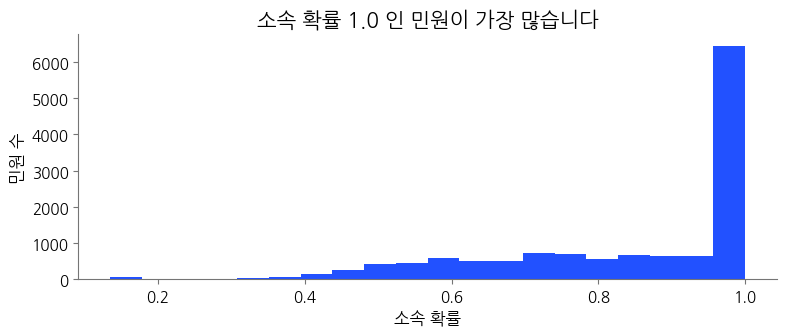

In [3]:
# 자료 준비 · 그림: 토픽에 속한 민원의 소속 확률 분포
p_in = SAMPLE.loc[t0 != -1, "prob_s0"]
print(f"토픽에 속한 민원 {len(p_in):,}건 가운데 소속 확률 1.0 인 민원 {int((p_in >= 1).sum()):,}건")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(p_in, bins=20, color="#2251FF")
ax.set_xlabel("소속 확률")
ax.set_ylabel("민원 수")
ax.set_title("소속 확률 1.0 인 민원이 가장 많습니다")
plt.show()

토픽에 속한 민원 전체에서 소속 확률이 가장 큰 값 1.0 인 막대가 가장 높습니다. 이론에서 본 것처럼 토픽마다 보아도 1.0 인 민원이 여럿입니다. 그래서 소속 확률로는 대표 문서 1건을 정할 수 없습니다. 대표 문서는 `DOC_SIM` 이 가장 큰 민원으로 고릅니다.

## 단계 1 원문 읽기

상위 단어만 보고는 토픽이 사건 하나를 말하는지 알 수 없습니다. 그래서 토픽마다 원문 5건을 읽습니다.

- **대표 문서** 1건: 대표 문서 점수(`DOC_SIM`)가 가장 큰 민원. 같으면 소속 확률이 큰 쪽
- **무작위 문서** 3건: 토픽의 민원 가운데 무작위로 고른 민원
- **경계 문서** 1건: 소속 확률이 가장 낮은 민원

난수 시드를 고정했으므로 누가 실행해도 같은 5건이 나옵니다. 이 방법으로 고르면 과정 결과의 원문 검토 표(토픽 0～9)와 같은 5건이 나옵니다.

판단 기준은 이론과 같습니다. 무작위 · 경계 4건 가운데 2건 이상이 대표 문서와 다른 제품이나 사건이면 **사건이 여럿인 토픽**입니다. 1건 이하면 **사건이 하나인 토픽**입니다.

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Simple_random_sampling.PNG" alt="왼쪽에 번호 1부터 12까지 사람 모양 12개가 있고, 그 가운데 2 · 5 · 8 · 10 번에서 화살표가 오른쪽 Sample 상자 4개로 이어진다" width="480" height="373"/>
<p align="center"><em>▲ 모집단 12명(Population)에서 4명(Sample)을 단순 무작위로 추출하는 그림. 누구나 추출될 확률이 같다. 무작위 문서 3건도 토픽의 민원에서 이렇게 고른다 (출처: Wikimedia Commons 「Simple random sampling.PNG」, Dan Kernler, CC BY-SA 4.0)</em></p>

<img src="https://ebhtmardjzsiyxjncvbb.supabase.co/storage/v1/object/public/images/12-nlp-unstructured/hdbscan-how-it-works-20-1.png" alt="평면 위의 점들이 초록 군집, 빨강 군집, 아래쪽 파란 곡선, 세 군집으로 나뉘고, 군집 바깥쪽 몇 점은 색이 옅거나 회색인 산점도" width="480" height="331"/>
<p align="center"><em>▲ HDBSCAN 결과. 같은 색 안에서 옅은 점일수록 소속 확률이 낮고, 회색 점은 어느 군집에도 속하지 않은 이상치다. 경계 문서는 토픽 안에서 가장 옅은 점에 해당한다 (출처: hdbscan 공식 문서 「How HDBSCAN Works」, BSD-3-Clause, 합성 자료)</em></p>

아래 셀은 토픽 40개마다 원문 5건을 한 번에 골라 `READ_TABLE` 에 저장하고, 토픽 0 을 출력합니다.

In [4]:
# 단계 1: 토픽마다 대표 1건 · 무작위 3건 · 경계 1건을 골라 READ_TABLE 에 저장합니다
p0 = SAMPLE["prob_s0"].to_numpy()
rng = np.random.default_rng(0)                        # 난수 생성기 하나를 토픽 0 부터 이어 씁니다
picks = []
for k in range(n_topics):
    idx = np.flatnonzero(t0 == k)
    top = idx[np.lexsort((-p0[idx], -DOC_SIM[idx]))[0]]   # 대표: DOC_SIM 최대, 같으면 소속 확률이 큰 쪽
    picks += [(k, "대표", top)] + [(k, "무작위", i) for i in rng.choice(idx, 3, replace=False)]
    picks.append((k, "경계", idx[np.argmin(p0[idx])]))    # 경계: 소속 확률이 가장 낮은 민원
READ_TABLE = pd.DataFrame([{"토픽": k, "종류": kind, "민원 제목": SAMPLE["사건제목"].iloc[i],
                            "품목명": SAMPLE["품목명"].iloc[i], "소속 확률": rnd(p0[i], 4)}
                           for k, kind, i in picks])


def read_topic(t):
    # 토픽 t 의 민원 수 · 상위 단어 · 원문 5건을 출력합니다
    print(f"토픽 {t} · 민원 {int((t0 == t).sum()):,}건 · 상위 단어: {' · '.join(TOPIC_WORDS[t])}")
    print(READ_TABLE[READ_TABLE["토픽"] == t].drop(columns="토픽").to_string(index=False))


read_topic(0)

토픽 0 · 민원 1,525건 · 상위 단어: 개통 · 요금 · 휴대폰 · 철회 · 인터넷
  종류                                민원 제목           품목명  소속 확률
  대표 개통하지 않은 휴대폰 요금 지출에 관한 건   이동전화서비스     1.0000
무작위 휴대폰 교체후 발생한 과다 위약금 피해건.         스마트폰     1.0000
무작위            기기값 과다청구로인한철회요청   이동전화서비스     0.7455
무작위               이동전화 관리감독 기관문의   이동전화서비스     0.6592
  경계        동의없던 요금 자동출금되어 문의 2 기타미분류서비스     0.5217


토픽 0 의 무작위 · 경계 4건은 모두 대표 문서와 다른 사건을 말합니다.

- 대표 문서는 개통하지 않은 휴대폰의 요금입니다.
- 나머지 4건은 위약금 · 기기값 청구 · 관리감독 기관 문의 · 요금 자동 출금입니다.

4건이 다르므로 토픽 0 은 사건이 여럿인 토픽입니다. 대표 문서와 첫째 무작위 문서는 소속 확률이 둘 다 1.0 인데도 사건이 다릅니다. 소속 확률이 높다고 같은 사건인 것은 아닙니다.

이번에는 헬스장 토픽 3 을 읽습니다.

In [5]:
# 단계 1: 토픽 3 의 원문 5건
read_topic(3)

토픽 3 · 민원 566건 · 상위 단어: 헬스장 · 헬스 · 중도 · 해지 · 환불
  종류                                  민원 제목                품목명  소속 확률
  대표                 헬스장 해지 빠른 환불 요청                헬스장     1.0000
무작위           헬스장 중도해지시 환불 규정 문의                헬스장     0.7362
무작위                 휘트니스 계약 후 해지 문의                헬스장     0.7223
무작위                헬스장 등록후 당일 취소요청                헬스장     0.9561
  경계 중도해지한 음악 연습실 대금 환급 가능 문의 기타문화·오락시설이용     0.4548


토픽 3 은 무작위 3건이 모두 헬스장 · 휘트니스의 해지 · 취소입니다. 대표 문서와 다른 민원은 경계 문서 1건뿐이고, 제품만 다른 음악 연습실 민원입니다. 그래서 토픽 3 은 사건이 하나인 토픽입니다.

경계 문서처럼 판단이 갈릴 민원은 단계 4 에서 넣을지 뺄지 정해 포함 기준이나 제외 기준에 적습니다.

이제 토픽 4～7 가운데 하나를 골라 직접 읽습니다. 아래 셀의 `MY_TOPIC` 을 바꿔 실행합니다.

In [6]:
# 단계 1 · 직접 해 보기: 토픽 4～7 가운데 하나를 골라 원문 5건을 읽습니다
MY_TOPIC = 4
read_topic(MY_TOPIC)
print()

MY_TOPIC = 5
read_topic(MY_TOPIC)
print()

MY_TOPIC = 6
read_topic(MY_TOPIC)
print()

MY_TOPIC = 7
read_topic(MY_TOPIC)

토픽 4 · 민원 478건 · 상위 단어: 정수기 · 렌탈 · 코웨이 · 비데 · 지연
  종류                                                 민원 제목           품목명  소속 확률
  대표        코웨이 정수기렌탈 AS지연으로 인한 불만 및 계약해지           정수기     0.4678
무작위        비데 대여 수리 일정 번복 지연되어 조속한 수리 요청              NaN     0.5891
무작위     정수기 잦은고장으로 제품교환 및 미사용금액 감액요청 5 정수기대여(렌트)     0.9651
무작위                               코웨이 정수기 계약해지 요청 정수기대여(렌트)     0.4714
  경계 밭과 집에서 사용중인 수돗물 밭에서 사용중인 수도 단수문의           수돗물     0.4143

토픽 5 · 민원 472건 · 상위 단어: 세탁 · 심의 · 배상 · 점퍼 · 훼손
  종류                                                                     민원 제목     품목명  소속 확률
  대표                                                                     세탁 피해     원피스     1.0000
무작위                                     더아이잡 매장  원피스구입후 변색으로 문의     원피스     0.5516
무작위                                          수선 후 가위로 찝힌 흔적이 있는 의류 스포츠웨어     0.8345
무작위 전문 세탁업자가 취급표시가 없는 의류를 세탁하다 사고가 난 경우 보상 주체 문의     원피스     1.0000
  경계                                           에어가 터진 운동화에 대한 보상 문

**직접 해 보기: 원문 검토 결과 적기**

읽은 토픽마다 사건이 여럿인지 하나인지 `MY_READ` 에 적습니다. 토픽 0 · 3 과 직접 고른 토픽을 적습니다. 더 읽어 보고 싶으면 `read_topic(5)` 처럼 실행해 토픽을 늘려도 됩니다.

- 키는 토픽 번호(0～7), 값은 `"여럿"` 또는 `"하나"` 입니다. 예: `MY_READ = {0: "여럿", 3: "하나"}`
- 무작위 · 경계 4건 가운데 대표 문서와 다른 제품이나 사건이 몇 건인지 먼저 정합니다.
- 확인 셀은 과정 결과의 원문 검토 결과와 비교하고, 토픽마다 여럿 · 하나로 본 이유를 보여 줍니다.

In [7]:
# 단계 1 · 직접 해 보기: {토픽 번호: "여럿" 또는 "하나"}
MY_READ = {0: "여럿", 1: "하나", 2: "여럿", 3: "하나", 6: "여럿", 4: "여럿", 7: "하나", 5:"여럿"}

In [8]:
# 단계 1 · 확인 셀: MY_READ 를 과정 결과의 원문 검토 결과(토픽 0～7)와 비교합니다
REVIEW = {0: "여럿", 1: "하나", 2: "여럿", 3: "하나", 4: "여럿", 5: "여럿", 6: "여럿", 7: "하나"}
WHY = {0: "무작위 · 경계 4건이 모두 대표 문서와 다른 사건입니다",
       1: "경계 1건(식당 계약 해지)만 다른 제품입니다",
       2: "자전거 사고 · 중고 오토바이 · 조리기기가 다른 제품입니다",
       3: "경계 1건(음악 연습실)만 다른 제품입니다",
       4: "비데 · 수돗물은 다른 제품이고, 잦은 고장 교환도 사건이 다릅니다",
       5: "변색 · 수선 흔적 · 운동화 보상이 세탁 사고와 다른 사건입니다",
       6: "인원 조정 2건과 사진 촬영 취소가 해지 위약금과 다릅니다",
       7: "경계 1건(로또 환불)만 다른 제품입니다"}


def check_read(my):
    if not my:
        print("아직 채우지 않았습니다. 위 셀의 MY_READ 를 채운 뒤 다시 실행합니다")
        return
    bad = [k for k, v in my.items() if k not in REVIEW or v not in ("여럿", "하나")]
    if bad:
        print(f"고칠 것: 키는 토픽 0～7, 값은 \"여럿\" 또는 \"하나\"로 적습니다(문제가 있는 키 {bad})")
        return
    same = sum(my[k] == REVIEW[k] for k in my)
    print(f"과정 결과와 같은 토픽 {same}개 / 적은 토픽 {len(my)}개")
    for k in sorted(my):
        mark = "같음" if my[k] == REVIEW[k] else "다름"
        print(f"토픽 {k} {mark}: 과정 결과는 사건이 {REVIEW[k]} · {WHY[k]}")


check_read(globals().get("MY_READ", {}))

과정 결과와 같은 토픽 8개 / 적은 토픽 8개
토픽 0 같음: 과정 결과는 사건이 여럿 · 무작위 · 경계 4건이 모두 대표 문서와 다른 사건입니다
토픽 1 같음: 과정 결과는 사건이 하나 · 경계 1건(식당 계약 해지)만 다른 제품입니다
토픽 2 같음: 과정 결과는 사건이 여럿 · 자전거 사고 · 중고 오토바이 · 조리기기가 다른 제품입니다
토픽 3 같음: 과정 결과는 사건이 하나 · 경계 1건(음악 연습실)만 다른 제품입니다
토픽 4 같음: 과정 결과는 사건이 여럿 · 비데 · 수돗물은 다른 제품이고, 잦은 고장 교환도 사건이 다릅니다
토픽 5 같음: 과정 결과는 사건이 여럿 · 변색 · 수선 흔적 · 운동화 보상이 세탁 사고와 다른 사건입니다
토픽 6 같음: 과정 결과는 사건이 여럿 · 인원 조정 2건과 사진 촬영 취소가 해지 위약금과 다릅니다
토픽 7 같음: 과정 결과는 사건이 하나 · 경계 1건(로또 환불)만 다른 제품입니다


<details class="lms-extra"><summary>자세히 — 예시 답</summary>

`MY_READ = {0: "여럿", 3: "하나", 6: "여럿"}` 이 예시 답입니다. 토픽 6 을 고른 경우입니다.

- 토픽 6 의 대표 문서는 결혼 예식 해지의 위약금입니다.
- 무작위 2건은 인원 수정 · 식사 인원 조정이고, 경계 문서는 결혼식 사진 촬영 취소입니다.
- 4건 가운데 3건이 달라 사건이 여럿인 토픽입니다.

토픽 0～7 의 과정 결과는 사건이 여럿인 토픽 5개(0 · 2 · 4 · 5 · 6), 하나인 토픽 3개(1 · 3 · 7)입니다. 사건이 여럿인 토픽도 테마에서 빼지 않습니다. 이름을 정한 뒤 사건마다 원문을 인용합니다.

</details>

> **[문제] 무작위 1건과 경계 1건이 다른 사건인 토픽**
>
> 예를 들어 어느 토픽의 5건을 읽었더니 무작위 1건과 경계 1건이 대표 문서와 다른 사건을 말한다고 합시다. 이 토픽의 원문 검토 결과와 다음 할 일로 맞는 것은 무엇일까요?
>
> 1. 사건이 하나인 토픽: 경계 문서는 원래 가장자리라 빼고 판단한다
> 2. 사건이 여럿인 토픽: 테마 후보로 두고 사건마다 원문을 인용한다
> 3. 사건이 여럿인 토픽: 한 이름으로 부르기 어려워 테마 후보에서 뺀다

## 단계 2 시드 안정성

시드만 바꿔 다시 적합해도 같은 토픽이 나와야 테마로 쓸 수 있습니다. 시드 0 의 토픽마다 시드 1 · 2 에서 가장 많이 겹치는 토픽을 찾습니다.

**자카드 계수(Jaccard coefficient)** 는 두 토픽에 함께 있는 민원 수를 어느 한쪽에라도 있는 민원 수로 나눈 값입니다. 두 토픽의 민원이 같으면 1, 하나도 겹치지 않으면 0 입니다.

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Venn0001.svg" alt="겹친 두 원 가운데 겹친 면만 빨갛게 칠한 벤 다이어그램" width="320" height="233" />
<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Venn0111.svg" alt="겹친 두 원 전체를 빨갛게 칠한 벤 다이어그램" width="320" height="236" />
<p align="center"><em>▲ 원 하나가 토픽 하나의 민원 집합이다. 왼쪽 그림의 빨간 면은 두 토픽에 함께 있는 민원(분자)이고, 오른쪽 그림의 빨간 면은 어느 한쪽에라도 있는 민원(분모)이다 (출처: Wikimedia Commons 「Venn0001.svg」 · 「Venn0111.svg」, Watchduck, 퍼블릭 도메인)</em></p>

- 다른 시드에서 자카드 계수가 가장 큰 토픽의 값이 0.5 이상이면 **대응 토픽**이 있다고 봅니다.
- 시드 1 · 2 를 모두 보고, 두 값 가운데 작은 값으로 판단합니다.
- 이상치(−1)는 대응 토픽 후보에서 뺍니다.

토픽 번호는 시드마다 따로 매깁니다. 그래서 시드 1 의 토픽 3 은 시드 0 의 토픽 3 과 다른 토픽일 수 있습니다.

**ARI(수정 Rand 지수)** 는 두 적합이 민원 두 건의 짝을 똑같이 나누는 정도를 수 하나로 나타냅니다. 짝마다 같은 토픽인지 다른 토픽인지가 두 적합에서 같은지 봅니다. 우연히 일치하는 정도를 빼므로, 무작위 배정이면 0 근처이고 완전히 같으면 1 입니다.

<img src="https://scikit-learn.org/stable/_images/sphx_glr_plot_adjusted_for_chance_measures_001.png" alt="가로축은 군집 수 2부터 100, 세로축은 지표 값. 주황 삼각형 Rand index 는 군집 수 2 에서 0.5 이고 10 을 넘으면 0.8 이상이다. 초록 역삼각형 ARI 는 모든 군집 수에서 0 근처다" width="480" height="360"/>
<p align="center"><em>▲ 10개 범주로 나눈 참조 배정과, 군집 수를 바꿔 가며 무작위로 나눈 배정을 비교한 그림. 주황 Rand 지수는 군집 수가 10을 넘으면 0.8 을 넘고, 초록 ARI 는 0 근처다 (출처: scikit-learn 공식 예제 「Adjustment for chance in clustering performance evaluation」, BSD-3-Clause, 합성 자료)</em></p>

In [9]:
# 단계 2: 시드 0 토픽마다 시드 1 · 2 의 대응 토픽 후보와 자카드 계수, 세 쌍 ARI
from sklearn.metrics import adjusted_rand_score
MATCH_MIN = 0.5                                       # 이 값 이상이면 대응 토픽이 있다고 봅니다
s1, s2 = SAMPLE["topic_s1"].to_numpy(), SAMPLE["topic_s2"].to_numpy()


def best_match(b, k):
    # 시드 0 의 토픽 k 와 자카드 계수가 가장 큰 b 의 토픽(−1 제외)과 그 값
    a = t0 == k
    jac = {j: (a & (b == j)).sum() / (a | (b == j)).sum() for j in np.unique(b[a]) if j != -1}
    j = max(jac, key=jac.get)
    return int(j), jac[j]


rows = []
for k in range(n_topics):
    (j1, v1), (j2, v2) = best_match(s1, k), best_match(s2, k)
    rows.append({"토픽": k, "민원 수": int((t0 == k).sum()), "시드 1 후보": j1, "시드 1 계수": rnd(v1, 2),
                 "시드 2 후보": j2, "시드 2 계수": rnd(v2, 2), "작은 값": min(v1, v2)})
MATCH = pd.DataFrame(rows)
aris = [adjusted_rand_score(x, y) for x, y in ((t0, s1), (t0, s2), (s1, s2))]   # −1 도 토픽 하나로 봅니다
print(f"작은 값이 {MATCH_MIN} 이상인 토픽 {int((MATCH['작은 값'] >= MATCH_MIN).sum())}개 / 시드 0 토픽 {n_topics}개")
print("세 쌍 ARI(시드 0·1 · 0·2 · 1·2): " + " · ".join(str(rnd(v, 4)) for v in aris))
print(MATCH.sort_values("작은 값").head(5).round({"작은 값": 2}).to_string(index=False))

작은 값이 0.5 이상인 토픽 39개 / 시드 0 토픽 40개
세 쌍 ARI(시드 0·1 · 0·2 · 1·2): 0.8212 · 0.8406 · 0.8214
 토픽  민원 수  시드 1 후보  시드 1 계수  시드 2 후보  시드 2 계수  작은 값
   36      109            3         0.19            4         0.19     0.19
   13      322            3         0.57            4         0.57     0.57
   19      238           26         0.59           15         0.74     0.59
   12      330           23         0.60           22         0.61     0.60
   32      137           36         0.70           31         0.72     0.70


아래 그림의 가로축은 토픽의 민원 수(로그 스케일), 세로축은 시드 1 · 2 의 자카드 계수 가운데 작은 값입니다. 점 하나가 시드 0 의 토픽 하나이고, 회색 점선이 기준 0.5 입니다. 출력의 표는 `작은 값` 이 가장 낮은 토픽 5개였고, 그림은 토픽 40개 전체입니다.

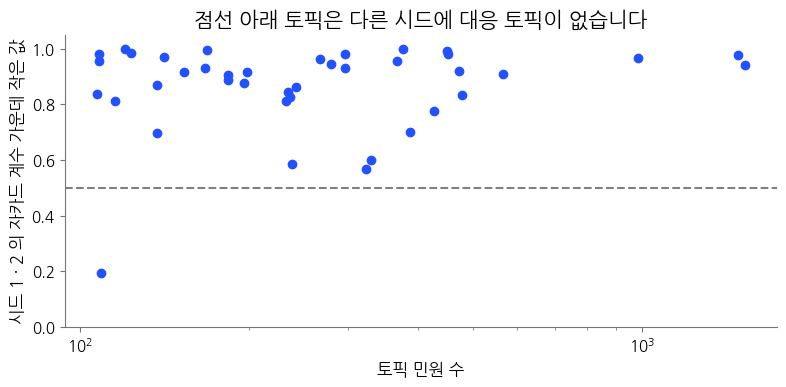

In [10]:
# 단계 2 · 그림: 토픽 민원 수와 시드 1 · 2 의 자카드 계수 가운데 작은 값
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(MATCH["민원 수"], MATCH["작은 값"], color="#2251FF")
ax.axhline(MATCH_MIN, color="gray", linestyle="--")
ax.set_xscale("log")
ax.set_ylim(0, 1.05)
ax.set_xlabel("토픽 민원 수")
ax.set_ylabel("시드 1 · 2 의 자카드 계수 가운데 작은 값")
ax.set_title("점선 아래 토픽은 다른 시드에 대응 토픽이 없습니다")
plt.show()

세 쌍 ARI 는 0.82～0.84 로, 배정 전체는 우연보다 많이 일치합니다. 그래도 그림에는 점선 아래 점이 있습니다. ARI 가 높아도 토픽 하나하나가 다시 나오는지는 따로 확인해야 합니다.

**직접 해 보기: 대응 토픽이 없는 토픽**

출력과 그림에서 시드 1 · 2 의 자카드 계수 가운데 작은 값가 0.5 아래인 토픽을 찾습니다. 그 토픽 번호를 `MY_NO_MATCH` 에 목록으로 적습니다. 예: `MY_NO_MATCH = [12]`

In [11]:
# 단계 2 · 직접 해 보기: 대응 토픽이 없는 토픽 번호 목록
MY_NO_MATCH = [36]

In [12]:
# 단계 2 · 확인 셀: MY_NO_MATCH 를 출력의 결과와 비교합니다
def check_no_match(my):
    if not my:
        print("아직 채우지 않았습니다. 위 셀의 MY_NO_MATCH 를 채운 뒤 다시 실행합니다")
        return
    if not all(isinstance(k, (int, np.integer)) and 0 <= k < n_topics for k in my):
        print(f"고칠 것: 토픽 번호를 0～{n_topics - 1} 의 정수로 적습니다(예: [12])")
        return
    answer = set(MATCH.loc[MATCH["작은 값"] < MATCH_MIN, "토픽"])
    print("맞았습니다" if set(my) == answer else f"아직 다릅니다: 빠진 토픽 {sorted(answer - set(my))} · 정답에 없는데 적은 토픽 {sorted(set(my) - answer)}")
    for k in sorted(answer & set(my)):
        r = MATCH.loc[MATCH["토픽"] == k].iloc[0]
        for col, j in (("topic_s1", r["시드 1 후보"]), ("topic_s2", r["시드 2 후보"])):
            inside = SAMPLE[col].to_numpy() == j
            share = (inside & (t0 == k)).sum() / (t0 == k).sum()
            print(f"토픽 {k}({int(r['민원 수'])}건)은 시드 {col[-1]} 에서 {int(inside.sum())}건인 토픽에 {100 * share:.0f}% 가 속합니다")


check_no_match(globals().get("MY_NO_MATCH", []))

맞았습니다
토픽 36(109건)은 시드 1 에서 565건인 토픽에 100% 가 속합니다
토픽 36(109건)은 시드 2 에서 559건인 토픽에 100% 가 속합니다


토픽 36 의 민원은 다른 시드에서 사라지지 않았습니다. 109건이 모두 560건 안팎의 큰 의료 토픽에 함께 속했습니다. 시드 1 이면 계산은 이렇습니다.

```text
자카드 계수 = 함께 있는 109 ÷ 어느 한쪽에라도 있는 565(109 + 나머지 456) ≈ 0.19
```

큰 토픽이 커서 분모가 커지고, 그래서 0.5 에 못 미칩니다.

**전임 담당자의 판단**

전임 담당자는 토픽 36(선납 · 진료비 · 시술 · 성형 · 수술)을 「20대 새 이슈」로 보았습니다. 토픽 36 의 20대 비중이 전체 20대 비중의 2배를 넘는다는 근거였습니다. 이 판단을 지금은 쓸 수 없는 이유를 한 문장으로 생각해 봅니다.

<details class="lms-extra"><summary>자세히 — 예시 답</summary>

「토픽 36 은 다른 두 시드에서 큰 의료 토픽에 합쳐져 따로 나오지 않으므로, 시드 0 에서만 보인 20대 쏠림은 새 이슈의 근거가 되지 못한다.」

20대 비중 계산 자체는 틀리지 않았습니다. 토픽 36 의 20대 비중은 23.85% 로, 전체 10.88% 의 2.19배입니다. 그 토픽은 시드 한 번에서만 나온 결과입니다. 다시 적합하면 토픽 36 이 없는 토픽 표가 나옵니다.

</details>

> **[문제] ARI 가 높을 때 토픽마다 확인할 것**
>
> 예를 들어 시드만 바꾼 세 번의 적합에서 세 쌍 ARI 가 모두 0.9 였다고 합시다. 이것만으로 「테마 후보 8개가 모두 다른 시드에서 다시 나온다」고 적어도 될까요? 이유와 함께 무엇을 더 확인할지 한두 문장으로 적어 보세요.

## 단계 3 이름 확인

토픽 3 의 LLM 이름 초안은 「해지 환불 민원」이었습니다. 코드북 v0 을 만들 때 첫 10건(표본 1)은 10건 모두 맞았습니다. 그런데 이 이름에는 시설이 없어, 여행 · 예식 등 여러 분야의 해지 환불에 두루 맞는 넓은 이름입니다.

그래서 헬스장 · 운동 강습을 더해 「헬스장·운동 강습 중도 해지 환불」로 고쳤습니다. 고친 이름은 같은 10건이 아니라 새로 고른 10건(표본 2)으로 다시 확인합니다. 같은 10건은 이미 이름을 고치는 데 썼기 때문입니다.

판단 기준은 이론과 같습니다.

- **시설**: 헬스장이나 운동 강습(PT · 폴댄스 등)
- **사건**: 해지 · 개시 전 취소 · 환불 · 해지에 따른 위약금. 취소 · 위약금도 해지와 같은 사건으로 봅니다
- **맞음**: 시설과 사건이 함께 맞는 민원. **아님**: 둘 가운데 하나라도 맞지 않는 민원
- 10건 가운데 8건 이상 맞아야 이름으로 씁니다. 8건은 95% 구간(Wald)의 하한이 0.5 를 넘는 가장 작은 건수입니다.

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/NYW-confidence-interval.svg" alt="파란 세로선 수십 개와 가운데를 가로지르는 분홍 점선 μ" width="520" height="213" />
<p align="center"><em>▲ 파란 세로선 하나가 표본 한 번으로 만든 95% 구간이고, 분홍 점선 μ 는 참값이다. 대부분은 μ 를 지나가고 몇 개는 점선과 만나지 않는다. 무작위 10건 한 번의 구간도 이 세로선 하나와 같다 (출처: Wikimedia Commons 「NYW-confidence-interval.svg」, Tsyplakov, 퍼블릭 도메인)</em></p>

아래 셀은 표본 2 의 10건을 출력합니다. 민원 제목의 전화번호는 [전화번호] 로 가려져 있습니다.

In [13]:
# 단계 3: 코드북 v0 의 토픽 3 이름 확인 표본(표본 2) 10건
check3 = CB_ROWS[3]["검산"][1]                         # 표본 2: 고친 이름으로 새로 고른 10건
NAME3 = check3["이름"]
NAME_SAMPLE = SAMPLE.set_index("row_id").loc[check3["row_id"], ["사건제목", "품목명"]].reset_index(drop=True)
NAME_SAMPLE.index = range(1, 11)
print(f"이름: {NAME3} · 토픽 3 에서 무작위로 고른 10건")
print(NAME_SAMPLE.to_string())

이름: 헬스장·운동 강습 중도 해지 환불 · 토픽 3 에서 무작위로 고른 10건
                                                             사건제목  품목명
1                                        휘트니스 계약 해지 관련 문의  헬스장
2                                              폴댄스 학원 해지위약금  헬스장
3                             헬스장에서 핸드폰 틈사이 빠져서 문의 10  헬스장
4                                헬스장 중도해지 환급금 관련 정보요구  헬스장
5                                         헬스장 계약금 환불관련 내용  헬스장
6              헬스장 업체 대표가 변경되어 계약내용이  달라졌다고 함.  헬스장
7                               휄스장등록 운동개시전 해지 환급관련건  헬스장
8                <소비생활센터 인입> 헬스 계약 취소 요청했으나 거부함  헬스장
9   개인PT  마스크 착용안하는 회원으로 인한 개시전  위약금 부당  문의  헬스장
10                                        헬스장 중도해지시 환불 요청  헬스장


**직접 해 보기: 맞음 · 아님 적기**

10건을 차례로 읽고, 이름에 맞으면 1, 아니면 0 을 `MY_MARKS` 에 적습니다. 예: `MY_MARKS = [1, 0, 1, 1, 1, 1, 1, 1, 1, 1]`

- 시설과 사건이 함께 맞는지 봅니다. 「헬스장」이 있어도 해지 · 취소 · 환불 · 위약금이 아니면 아님입니다.
- 확인 셀은 맞은 건수 · 95% 구간 · 기준 통과 여부를 출력합니다.
- 과정 결과의 AI 판단과 몇 건이 같은지, 어느 민원이 다른지도 출력합니다. AI 판단은 사람이 라벨한 정답이 아니므로 다르다고 틀린 것은 아닙니다.

In [14]:
# 단계 3 · 직접 해 보기: 1번부터 10번까지 맞음 1 · 아님 0
MY_MARKS = [1, 1, 0, 1, 1, 0, 1, 0, 0, 1]

In [15]:
# 단계 3 · 확인 셀: 맞은 건수 · 95% 구간(Wald) · 기준 8건 · AI 판단과의 비교
def check_marks(my):
    if not my:
        print("아직 채우지 않았습니다. 위 셀의 MY_MARKS 를 채운 뒤 다시 실행합니다")
        return
    if len(my) != 10 or any(m not in (0, 1) for m in my):
        print(f"고칠 것: 0 또는 1 을 10개 적습니다(지금 {len(my)}개)")
        return
    n = sum(my)
    p = n / 10
    moe = 1.96 * np.sqrt(p * (1 - p) / 10)                 # 오차 한계
    print(f"맞은 건수 {n}/10 · 기준 8건 {'통과' if n >= 8 else '통과하지 못함'}")
    print(f"95% 구간 {max(0, p - moe):.2f}～{min(1, p + moe):.2f} · 하한이 0.5 를 넘는가: {'예' if p - moe > 0.5 else '아니오'}")
    ai = check3["판단"]
    diff = [i for i in range(10) if my[i] != ai[i]]
    print(f"AI 판단과 같은 민원 {10 - len(diff)}건 · AI 판단은 사람이 라벨한 정답이 아닙니다")
    for i in diff:
        print(f"{i + 1}번 나 {'맞음' if my[i] else '아님'} · AI {'맞음' if ai[i] else '아님'}: {NAME_SAMPLE.loc[i + 1, '사건제목']}")


check_marks(globals().get("MY_MARKS", []))

맞은 건수 6/10 · 기준 8건 통과하지 못함
95% 구간 0.30～0.90 · 하한이 0.5 를 넘는가: 아니오
AI 판단과 같은 민원 8건 · AI 판단은 사람이 라벨한 정답이 아닙니다
8번 나 아님 · AI 맞음: <소비생활센터 인입> 헬스 계약 취소 요청했으나 거부함
9번 나 아님 · AI 맞음: 개인PT  마스크 착용안하는 회원으로 인한 개시전  위약금 부당  문의


아래 그림의 가로축은 10건 가운데 맞은 건수, 세로축은 이름에 맞는 비율의 95% 구간입니다. 세로 막대 하나가 구간 하나이고, 회색 점선이 0.5 입니다. `MY_MARKS` 를 채웠다면 내 건수의 구간이 하늘색으로 보입니다.

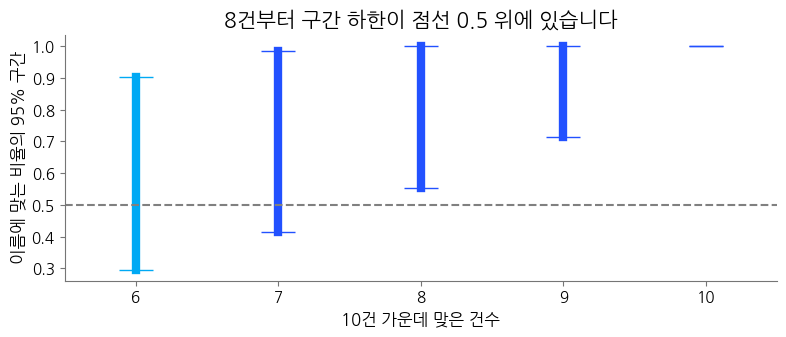

In [16]:
# 단계 3 · 그림: 맞은 건수 6～10건의 95% 구간(Wald)과 기준선 0.5
mine = sum(globals().get("MY_MARKS", [])) if len(globals().get("MY_MARKS", [])) == 10 else None
fig, ax = plt.subplots(figsize=(8, 3.5))
for n in range(6, 11):
    p = n / 10
    moe = 1.96 * np.sqrt(p * (1 - p) / 10)
    ax.plot([n, n], [max(0, p - moe), min(1, p + moe)], color="#00A9F4" if n == mine else "#2251FF",
            linewidth=6, marker="_", markersize=24)            # 10건이면 구간 길이가 0 이라 가로 표시만 보입니다
ax.axhline(0.5, color="gray", linestyle="--")
ax.set_xticks(range(6, 11))
ax.set_xlim(5.5, 10.5)
ax.set_xlabel("10건 가운데 맞은 건수")
ax.set_ylabel("이름에 맞는 비율의 95% 구간")
ax.set_title("8건부터 구간 하한이 점선 0.5 위에 있습니다")
plt.show()

8건부터 구간 하한이 0.5 위입니다. 7건 이하는 구간이 점선을 지나 이름을 쓰지 않습니다.

<details class="lms-extra"><summary>자세히 — 예시 답</summary>

`MY_MARKS = [1, 1, 0, 1, 1, 0, 1, 1, 1, 1]` 이 예시 답이고, 과정 결과의 AI 판단과 같습니다.

- 3번 「헬스장에서 핸드폰 틈사이 빠져서 문의」는 헬스장이지만 해지 · 환불이 아닙니다.
- 6번 「업체 대표가 변경되어 계약내용이 달라졌다」는 계약 변경 민원이고, 해지 · 환불 요청이 아닙니다.
- 2번 「폴댄스 학원 해지위약금」은 운동 강습(폴댄스)의 해지 위약금이라 맞음입니다.
- 5번 「헬스장 계약금 환불관련 내용」은 헬스장의 계약금 환불이라 맞음입니다.
- 8번 「헬스 계약 취소 요청했으나 거부함」은 헬스장 계약의 취소라 맞음입니다.
- 9번 「개인PT … 개시전 위약금 부당 문의」는 PT 의 개시 전 위약금이라 맞음입니다.

8/10 이라 기준은 통과합니다. 다만 하한이 0.5 에 가까워, 이 이름을 쓸 때마다 새 10건으로 다시 확인합니다.

</details>

> **[문제] 고치지 않고 코드북에 적을 이름 초안**
>
> 「자료 준비」 셀을 실행하면 나오는 「표 2 · 토픽 0～7 의 LLM 이름 초안과 첫 확인에서 맞은 건수」를 봅니다. 이름 초안을 고치지 않고 코드북에 적을 수 있는 토픽은 어느 것일까요?
>
> 1. 토픽 3 · 4 · 7: 세 초안 모두 10건 가운데 8건 이상 맞았다
> 2. 토픽 4 · 7: 토픽 3 의 「해지 환불 민원」은 제품이 없는 넓은 이름이다
> 3. 토픽 0～7 모두: temperature 0 으로 만든 초안이라 다시 호출해도 같다

## 단계 4 코드북 항목 쓰기

**코드북**은 테마마다 이름 · 정의 · 포함 기준 · 제외 기준 · 예를 적은 표입니다. 여러 사람이 같은 민원을 같은 테마로 나누도록 기준을 글로 정합니다. 이름만 있으면 판단이 애매한 민원을 사람마다 다르게 나눕니다.

코드북 v0 의 토픽 3 항목은 포함 · 제외 기준에 원문 근거가 없는 일반적인 문장 두 개만 있습니다.

> 포함 기준: 제목·품목명이 이 이름에 들어맞는 민원
>
> 제외 기준: 다른 테마 이름이 더 잘 맞는 민원 → 그 테마, 어디에도 맞지 않으면 기타

두 문장에는 원문 이름이 없어, 단계 1 의 음악 연습실을 어느 쪽으로 분류할지 정하지 못합니다. 이번에는 단계 1～3 에서 읽은 원문을 근거로 기준을 직접 씁니다.

- **포함 기준**: 이 테마로 분류할 시설과 사건을 씁니다. 경계 문서(음악 연습실)처럼 판단이 갈릴 민원은 넣을지 뺄지 정해 포함 기준이나 제외 기준에 적습니다.
- **제외 기준**: 단계 3 에서 아님으로 판단한 민원을 다른 테마 이름이나 기타로 분류한다고 씁니다. 토픽 번호는 다시 적합하면 바뀌므로 쓰지 않습니다.
- **예**: 토픽 3 의 실제 민원 제목 2건을 글자 그대로 적습니다. 단계 1 · 3 의 출력에서 복사합니다.
- **원인**: 어떤 민원에 원인을 적고 어떤 민원은 비울지 씁니다. 예: 「민원 제목에 코로나 같은 원인이 있으면 적고, 없으면 비운다」. 토픽 3 에도 「코로나 바이러스로 헬스장 계약해제 문의」 같은 민원이 있습니다.

아래 그림은 토픽 3 민원의 품목명 상위 8개입니다. 가로축은 민원 수(로그 스케일)이고, 막대 하나가 품목 하나입니다. 포함 기준에 어떤 시설을 쓸지 이 그림으로 정합니다.

토픽 3 민원 566건의 품목명 상위: 헬스장 453 · 종합체육시설회원권 39 · 스포츠시설이용 12 · 피부·체형관리서비스 8 · 할인회원권 5 · 수영장회원권 5 · 기타사설강습서비스 5 · 기타미분류서비스 4
피부·체형관리서비스의 예: ['체형교정센터 등록후 개시전에  환불 요청', '에스테틱 개시일전 해지환불기준']


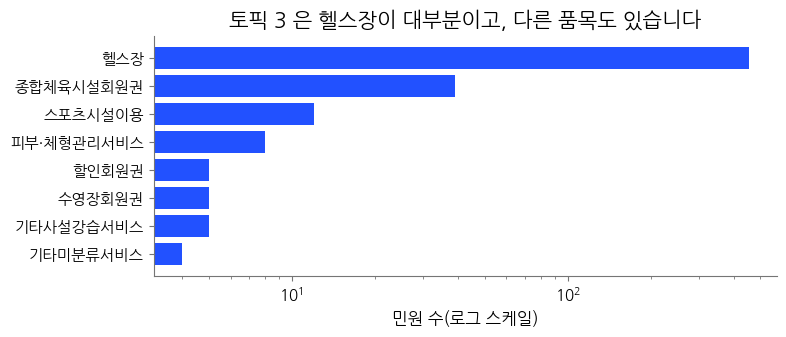

In [17]:
# 단계 4 · 그림: 토픽 3 민원의 품목명 상위 8개와, 운동 시설이 아닌 품목의 민원 제목
items = SAMPLE.loc[t0 == 3, "품목명"].value_counts().head(8)
print(f"토픽 3 민원 {int((t0 == 3).sum())}건의 품목명 상위: " + " · ".join(f"{k} {v}" for k, v in items.items()))
print("피부·체형관리서비스의 예:", SAMPLE.loc[(t0 == 3) & (SAMPLE["품목명"] == "피부·체형관리서비스"), "사건제목"].head(2).tolist())
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(items.index[::-1], items.values[::-1], color="#2251FF")
ax.set_xscale("log")
ax.set_xlabel("민원 수(로그 스케일)")
ax.set_title("토픽 3 은 헬스장이 대부분이고, 다른 품목도 있습니다")
plt.show()

In [18]:
print("헬스장의 예:", SAMPLE.loc[(t0 == 3) & (SAMPLE["품목명"] == "헬스장"), "사건제목"].head(2).tolist())
print("종합체육시설회원권의 예:", SAMPLE.loc[(t0 == 3) & (SAMPLE["품목명"] == "종합체육시설회원권"), "사건제목"].head(2).tolist())

헬스장의 예: ['헬스장 계약해지 관련 민원', '헬스장 해지 문의']
종합체육시설회원권의 예: ['헬스 등록시 추가 금액 지급 시 필라테스 운동 코로나19로 중지 연장 거절 문의', '헬스 중도해지 환불 규정 문의']


토픽 3 의 566건 가운데 헬스장이 453건입니다. 다음은 종합체육시설회원권 39건 · 스포츠시설이용 12건 · 수영장회원권 5건처럼 운동 시설 품목입니다.

피부·체형관리서비스 8건은 운동 시설이 아닙니다. 「체형교정센터 등록후 개시전에 환불 요청」 · 「에스테틱 개시일전 해지환불기준」처럼 해지 · 환불이지만 시설이 다릅니다. 코드북 기준에서 이런 품목을 포함할지 제외할지 정해야 합니다.

**직접 해 보기: 토픽 3 의 코드북 항목**

아래 `MY_ENTRY` 의 따옴표 안을 채웁니다. 「예」는 민원 제목 2건의 목록입니다. 확인 셀은 자동 확인 4가지를 봅니다.

- 비어 있는 항목이 없는가
- 「예」가 토픽 3 의 실제 민원 제목 2건인가
- 제외 기준에 토픽 번호(「토픽 27」 같은 것)가 없는가
- 제외 기준에 분류할 곳이 있는가. 분류할 곳은 「기타」나 정리 그림의 테마 이름입니다

뜻이 맞는지는 자동으로 보지 않습니다. 확인 셀이 출력하는 점검표 4줄로 스스로 봅니다.

In [19]:
# 단계 4 · 직접 해 보기: 토픽 3 의 코드북 항목
MY_ENTRY = {
    "이름": "헬스장",
    "정의": "운동, 체육, 스포츠 시설 이용에 대한 환불, 해지 관련 민원",
    "포함 기준": "헬스장 · 피트니스 · 필라테스 · 요가 · 수영 · 골프 연습장 · 댄스 같은 운동 시설과 강습(PT 포함)의 해지 · 환불 · 위약금 · 남은 횟수 환불",
    "제외 기준": "휴회 · 양도 · 불친절처럼 해지 · 환불이 아닌 이용 불만은 기타. 영어 · 수학 학원처럼 운동이 아닌 강습의 해지 · 환불은 학원 테마가 있으면 그 테마, 없으면 기타",
    "예": ["헬스장 계약해지 관련 민원", "헬스 중도해지 환불 규정 문의"],
    "원인": "코로나",
}

In [20]:
# 단계 4 · 확인 셀: 자동 확인 4가지만 봅니다. 뜻은 아래 점검표로 스스로 봅니다
import re
KEYS = ["이름", "정의", "포함 기준", "제외 기준", "예", "원인"]
TITLES3 = {" ".join(str(x).split()) for x in SAMPLE.loc[t0 == 3, "사건제목"]}
DESTS = ["기타"] + [r["테마"] for r in CB_ROWS.values()]


def check_entry(e):
    e = {k: e.get(k, "") for k in KEYS}
    if not any(str(v).strip() for k, v in e.items() if k != "예") and not any(str(x).strip() for x in e["예"]):
        print("아직 채우지 않았습니다. 위 셀의 MY_ENTRY 를 채운 뒤 다시 실행합니다")
        return
    ex = [" ".join(str(x).split()) for x in e["예"] if str(x).strip()]
    todo = []
    if [k for k in KEYS if k != "예" and not str(e[k]).strip()] or len(ex) != 2:
        todo.append("비어 있는 항목을 채우고, 예는 민원 제목 2건으로 적습니다")
    if [x for x in ex if x not in TITLES3]:
        todo.append(f"예가 토픽 3 의 민원 제목과 다릅니다: {[x for x in ex if x not in TITLES3]}")
    if re.search(r"토픽\s*\d+", e["제외 기준"]):
        todo.append("제외 기준에서 토픽 번호를 빼고 테마 이름이나 기타로 적습니다")
    if not any(d in e["제외 기준"] for d in DESTS):
        todo.append("제외 기준에 분류할 곳(테마 이름이나 기타)을 적습니다")
    print(f"자동 확인 4가지 가운데 통과 {4 - len(todo)}개")
    for t in todo:
        print("고칠 것: " + t)
    print("스스로 보는 점검표")
    print("1. 정의가 시설(운동 시설 · 강습)과 사건(해지 · 환불)을 둘 다 말하는가")
    print("2. 제외 기준이 단계 3 에서 아님으로 판단한 민원을 어느 테마로 분류할지 정하는가")
    print("3. 경계 문서처럼 판단이 갈릴 민원을 넣을지 뺄지 정했는가")
    print("4. 원인을 이름이 아니라 원인 항목에 적었는가")


check_entry(globals().get("MY_ENTRY", {}))

자동 확인 4가지 가운데 통과 4개
스스로 보는 점검표
1. 정의가 시설(운동 시설 · 강습)과 사건(해지 · 환불)을 둘 다 말하는가
2. 제외 기준이 단계 3 에서 아님으로 판단한 민원을 어느 테마로 분류할지 정하는가
3. 경계 문서처럼 판단이 갈릴 민원을 넣을지 뺄지 정했는가
4. 원인을 이름이 아니라 원인 항목에 적었는가


### 토픽 6 코드북 항목(이론)

이론에서는 토픽 6 「예식 취소·위약금」의 기준을 이름 확인의 원문으로 다시 썼습니다. 그대로 옮기지 말고, 내 항목과 무엇이 같고 다른지 비교합니다.

| 항목 | 토픽 6 「예식 취소·위약금」 |
|---|---|
| 정의 | 예식장·웨딩홀·결혼준비대행 계약을 취소·연기·변경하면서 생긴 위약금·계약금 문제에 관한 민원 |
| 포함 기준 | 민원 제목이 예식 계약의 취소·연기·인원 조정이나 그에 따른 위약금·계약금 환급을 말한다 |
| 제외 기준 | 돌잔치 · 뷔페 계약의 취소와 결혼정보업체 가입비는 예식 계약이 아니라 기타 |
| 예 | 「코로나로 인한 예식장해지문의」 · 「예식장 계약해제시 계약금 환급 문의」 |
| 원인 | 민원 제목에 코로나가 있으면 「코로나」, 없으면 비운다 |

- 제외 기준의 뷔페는 이름 확인에서 아님으로 판단한 민원입니다. 단계 3 의 3번 · 6번과 같은 경우입니다.
- 포함 기준의 연기는 이름의 「취소」와 다르지만 포함하기로 정한 사건입니다. 폴댄스나 PT 를 어느 쪽으로 분류할지 정하는 것과 같습니다.

<details class="lms-extra"><summary>자세히 — 예시 답</summary>

| 항목 | 토픽 3 「헬스장·운동 강습 중도 해지 환불」 |
|---|---|
| 정의 | 헬스장이나 운동 강습의 이용 계약을 중도에 해지하면서 생긴 환불 · 위약금 문제에 관한 민원 |
| 포함 기준 | 헬스장 · 휘트니스 · PT · 폴댄스 같은 운동 시설과 강습의 해지 · 개시 전 취소 · 환불 · 위약금 |
| 제외 기준 | 헬스장에서 생긴 분실이나 업체 대표 변경처럼 해지 · 환불이 아닌 민원은 기타. 음악 연습실 · 피부·체형관리처럼 운동 시설이 아닌 계약은 기타 |
| 예 | 「헬스장 중도해지시 환불 요청」 · 「폴댄스 학원 해지위약금」 |
| 원인 | 민원 제목에 코로나 같은 원인이 있으면 적고, 없으면 비운다 |

- 제외 기준의 분실 · 대표 변경은 단계 3 의 3번 · 6번입니다.
- 음악 연습실은 단계 1 의 경계 문서입니다. 운동 시설이 아니라 제외 기준에 적었습니다.
- 피부·체형관리처럼 운동 시설이 아닌 서비스도 기타로 분류합니다.
- 테마별 민원 건수는 코드북 기준이 아니라 토픽 배정으로 집계하므로, 기준을 고쳐도 건수는 그대로입니다.

</details>

## 결론

아래 그림에서 막대 하나가 테마 하나이고, 가로축은 민원 수입니다. 회색 막대는 테마에서 뺀 토픽 36 입니다.

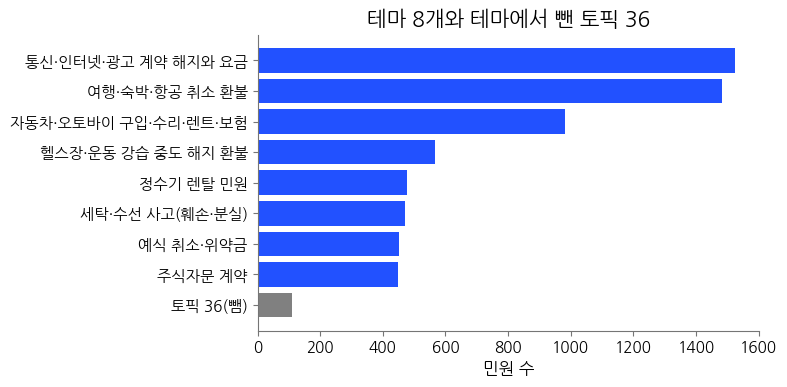

In [21]:
# 결론 · 그림: 테마로 쓸 토픽 0～7 과 뺀 토픽 36 의 민원 수
names = [CB_ROWS[k]["테마"] for k in THEMES] + ["토픽 36(뺌)"]
sizes = [int((t0 == k).sum()) for k in THEMES + [36]]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(names[::-1], sizes[::-1], color=["gray"] + ["#2251FF"] * 8)
ax.set_xlabel("민원 수")
ax.set_title("테마 8개와 테마에서 뺀 토픽 36")
plt.show()

<div class="lms-summary">

**정리**

- 원문 읽기: 토픽 0～7 가운데 5개는 사건이 여럿인 토픽입니다. 빼지 않고 사건마다 원문을 인용합니다.
- 시드 안정성: 토픽 40개 가운데 39개는 두 시드 모두 대응 토픽이 있습니다. 토픽 36 만 큰 의료 토픽에 합쳐집니다.
- 이름 확인: 토픽 3 의 고친 이름은 새 10건 가운데 8건이 맞았습니다(AI 판단). 쓸 때마다 새 10건으로 다시 확인합니다.
- 코드북: 이름 확인에서 아님으로 판단한 민원은 제외 기준의 근거입니다. 경계 문서처럼 판단이 갈릴 민원은 넣을지 뺄지 정해 적습니다. 제외한 민원은 테마 이름이나 기타로 분류합니다.

토픽 0～7 은 세 시드 모두 다시 나온 토픽 가운데 가장 큰 8개이고, 8개의 이름 확인은 이론에서 마쳤습니다. 이 실습에서는 토픽 3 의 이름 확인을 다시 해 봤습니다. 그래서 테마로 쓸 토픽은 3가지 확인을 모두 거친 토픽 0～7 이고, 토픽 36 은 테마 후보에서 뺍니다.

</div>

> **[과제] 실습 제출: 토픽 검증표와 코드북 항목**
>
> 직접 해 보기 4가지를 채우고 확인 셀을 실행한 상태로 노트북을 제출합니다. ① 단계 1 의 MY_READ ② 단계 2 의 MY_NO_MATCH ③ 단계 3 의 MY_MARKS ④ 단계 4 의 MY_ENTRY 를 채웁니다. 과정 결과와 판단이 달라도 확인 셀이 결과를 출력했으면 점수를 받습니다.
>
> 마감: 2026-11-09T23:59+09:00
>
> **평가 기준**
>
> | 기준 | 이렇게 하면 충족 | 배점 |
> | --- | --- | --- |
> | 단계 1 | 토픽 0 · 3 과 고른 토픽 하나 이상을 적었다(과정 결과와 달라도 확인 셀이 이유를 출력하면 점수) | 25 |
> | 단계 2 | MY_NO_MATCH 를 채웠고 확인 셀이 결과를 출력했다 | 10 |
> | 단계 3 | 10건을 모두 0 · 1 로 적었고 확인 셀이 맞은 건수와 95% 구간을 출력했다(AI 판단과 달라도 점수) | 25 |
> | 단계 4 | 확인 셀의 자동 확인 4가지를 모두 통과했다 | 40 |
>
> 제출은 LMS 레슨 화면의 과제 카드에서 GitHub 링크로 합니다(이 파일에 적으면 제출되지 않습니다).

<div style="background:#F2F2F2;color:#000000;padding:28px;border-radius:12px;border:1px solid #E6E6E6;margin-top:16px;border-left:4px solid #051C2C">
<h2 style="color:#000000;margin:0 0 8px 0">수고했습니다. 비정형 데이터(자연어) 토픽 검증 실습을 마쳤습니다</h2>
<div style="color:#656565">토픽을 원문 읽기 · 시드 안정성 · 이름 확인으로 검증하고, 토픽 3 의 코드북 항목을 원문을 근거로 썼습니다.</div>
</div>